# Netflix Movies & TV Shows: Exploratory Data Analysis

**Goal:** Clean the Netflix titles dataset and explore what the catalog is made of.

**Data:** Netflix Movies and TV Shows from Kaggle (8,807 titles, 12 columns)
**Tools:** Python, pandas, NumPy

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shivamb/netflix-shows/netflix_titles.csv


In [2]:
df = pd.read_csv('/kaggle/input/datasets/shivamb/netflix-shows/netflix_titles.csv')
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
df.shape

(8807, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


## Data Cleaning

**Goal:** Find and fix missing values so the analysis is reliable.

**Finding:** Director (2,634), country (831) and cast (825) had the most missing values. Date added, rating and duration had only a few each.
- Missing director and cast were replaced with "No Data".
- Missing country was replaced with "Unknown" so that no country's count is inflated.
- The few remaining rows with a missing date, rating or duration (under 0.2% of the data) were dropped.
- Duplicate rows were removed.

In [5]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [ ]:
# Replacements
df['country'] = df['country'].fillna('Unknown')
df['cast'] = df['cast'].fillna('No Data')
df['director'] = df['director'].fillna('No Data')

# Drop the few rows still missing date_added, rating or duration
df = df.dropna()

# Drop duplicates
df = df.drop_duplicates()

In [8]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

<Axes: xlabel='type'>

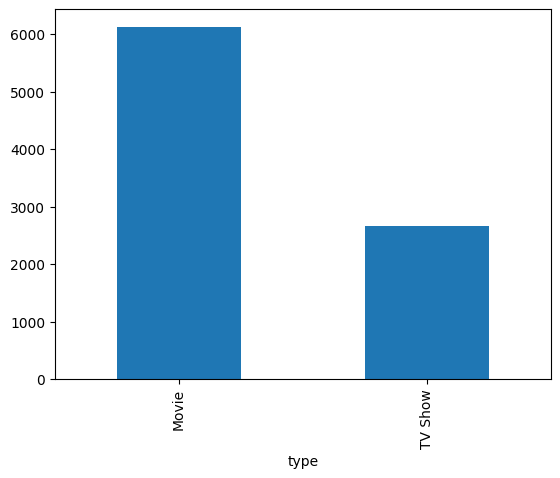

In [9]:
df['type'].value_counts().plot(kind='bar', title='Movies vs TV Shows')

In [ ]:
(df['type'].value_counts(normalize=True) * 100).round(1)

## Movies vs TV Shows

**Goal:** See how the catalog is split between movies and TV shows.

**Finding:** Movies make up about 70% of the catalog, so Netflix has far more movies than TV shows.

In [11]:
 df.groupby('release_year').size().idxmax()

np.int64(2018)

## Release Year

**Goal:** Find which release year has the most titles.

**Finding:** 2018 has the most titles of any release year in the dataset.

## Conclusion

- The Netflix catalog is mostly movies, with TV shows making up the smaller share.
- Titles released in 2018 are the largest group in the dataset.
- Missing values were concentrated in director, country and cast, and were handled without losing meaningful data.